# Fuga de empleados: factores, costo y modelo de riesgo

**Autora:** Eliana Salazar Laborí · **Herramientas:** Python (Pandas, SciPy, Scikit-learn, Matplotlib, Seaborn) · Tableau

**Origen:** basado en el caso *Tu primera semana como Data Scientist* de DS4B. Esta versión rehace el análisis con contrastes estadísticos, validación cruzada y un modelo comparado contra alternativas.

## Resumen ejecutivo

- **Tasa de abandono:** 16.1% (237 de 1,470 empleados). Con los porcentajes de costo de reemplazo del Center for American Progress, esas salidas cuestan cerca de **USD 2.72 millones**.
- **Factores con mayor asociación:** hacer horas extra (31% de abandono frente a 10%), el puesto (40% en *Sales Representative*), el nivel laboral más bajo, no tener acciones de la empresa, ser soltero y la baja satisfacción en el trabajo. Todos son estadísticamente significativos (chi-cuadrado, p < 0.001).
- **Modelo:** se comparó un modelo base, un árbol de decisión, un random forest y una regresión logística con validación cruzada. La regresión logística fue la mejor: **ROC-AUC de 0.83 en validación cruzada y 0.79 en el conjunto de prueba**. Contactando al 20% de empleados con mayor riesgo se captura el 56% de las salidas.
- **Uso:** 170 empleados activos (14%) quedan en riesgo alto y concentran el **39% del costo esperado** de la rotación (USD 729 mil de USD 1.89 millones). Son el grupo donde la retención rinde más.

## 1. Problema de negocio

La empresa pierde cada año a una parte de su plantilla. Cada salida tiene un costo de reemplazo (selección, inducción, curva de aprendizaje) que no se ve en ningún reporte.

**Preguntas:**
1. ¿Cuál es la tasa de abandono y qué características la acompañan?
2. ¿Cuánto le cuesta la rotación a la empresa?
3. ¿Se puede anticipar qué empleados activos tienen mayor riesgo de irse, para priorizar acciones de retención?

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, precision_score, recall_score, f1_score)

SEMILLA = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 2. Datos

Base de 1,470 empleados con 31 variables: datos demográficos, puesto, salario, satisfacción, antigüedad y si dejaron la empresa (`abandono`). Es una versión en español, preparada por DS4B, del conjunto ficticio *IBM HR Analytics Employee Attrition*.

> El archivo no se publica en el repositorio. Para reproducir el análisis, colócalo en `data/AbandonoEmpleados.csv`.

In [2]:
df = pd.read_csv("data/AbandonoEmpleados.csv", sep=";", index_col="id", na_values="#N/D")
print(f"Empleados: {len(df):,} | Variables: {df.shape[1]}")
df.head()

Empleados: 1,470 | Variables: 31


,edad,abandono,viajes,departamento,distancia_casa,educacion,carrera,empleados,satisfaccion_entorno,sexo,implicacion,nivel_laboral,puesto,satisfaccion_trabajo,estado_civil,salario_mes,num_empresas_anteriores,mayor_edad,horas_extra,incremento_salario_porc,evaluacion,satisfaccion_companeros,horas_quincena,nivel_acciones,anos_experiencia,num_formaciones_ult_ano,conciliacion,anos_compania,anos_en_puesto,anos_desde_ult_promocion,anos_con_manager_actual
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,41,Yes,Travel_Rarely,Sales,1,Universitaria,Life Sciences,1,Media,3.0,Alta,2,Sales Executive,Alta,Single,5993,8,Y,Yes,11,Alta,Baja,80,0,8,0,NaN,6,NaN,0,5
2,49,No,Travel_Frequently,Research & Development,8,Secundaria,Life Sciences,1,Alta,2.0,Media,2,Research Scientist,Media,Married,5130,1,Y,No,23,Muy_Alta,Muy_Alta,80,1,10,3,NaN,10,NaN,1,7
4,37,Yes,Travel_Rarely,Research & Development,2,Secundaria,Other,1,Muy_Alta,2.0,Media,1,Laboratory Technician,Media,Single,2090,6,Y,Yes,15,Alta,Media,80,0,7,3,NaN,0,2.0,0,0
5,33,No,Travel_Frequently,Research & Development,3,Universitaria,Life Sciences,1,Muy_Alta,3.0,Alta,1,Research Scientist,Alta,Married,2909,1,Y,Yes,11,Alta,Alta,80,0,8,3,NaN,8,3.0,3,0
7,27,No,Travel_Rarely,Research & Development,2,Universitaria,Medical,1,Baja,3.0,Alta,1,Laboratory Technician,Alta,Married,3468,9,Y,No,12,Alta,Muy_Alta,80,1,6,3,NaN,2,NaN,2,2


### 2.1 Calidad de datos

In [3]:
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
})
calidad[(calidad["% nulos"] > 0) | (calidad["valores únicos"] <= 1)]

,tipo,nulos,% nulos,valores únicos
educacion,str,101,6.9,4
empleados,int64,0,0.0,1
sexo,float64,199,13.5,4
implicacion,str,18,1.2,4
satisfaccion_trabajo,str,76,5.2,4
mayor_edad,str,0,0.0,1
horas_quincena,int64,0,0.0,1
conciliacion,str,1011,68.8,4
anos_en_puesto,float64,1238,84.2,4


In [4]:
print("Valores de 'sexo':", df["sexo"].value_counts(dropna=False).sort_index().to_dict())

Valores de 'sexo': {1.0: 74, 2.0: 328, 3.0: 739, 4.0: 130, nan: 199}


| Variable | Problema | Decisión |
|---|---|---|
| `anos_en_puesto` | 84% de nulos | Se elimina |
| `conciliacion` | 69% de nulos | Se elimina |
| `empleados`, `horas_quincena`, `mayor_edad` | Un solo valor para todos | Se eliminan: no aportan información |
| `sexo` | Codificada con 4 valores numéricos sin diccionario | Se elimina: no es interpretable |
| `educacion`, `satisfaccion_trabajo`, `implicacion` | Entre 1% y 7% de nulos | Se imputan con la moda **dentro del pipeline del modelo**, para que la imputación se aprenda solo con los datos de entrenamiento |

In [5]:
eliminar = ["anos_en_puesto", "conciliacion", "empleados", "horas_quincena", "mayor_edad", "sexo"]
df = df.drop(columns=eliminar)
df["abandono"] = (df["abandono"] == "Yes").astype(int)
print(f"Variables restantes: {df.shape[1] - 1} predictoras + abandono")

Variables restantes: 24 predictoras + abandono


## 3. ¿Quién deja la empresa?

### 3.1 Tasa de abandono

In [6]:
tasa = df["abandono"].mean()
print(f"Tasa de abandono: {tasa:.1%} ({df['abandono'].sum()} de {len(df):,} empleados)")

Tasa de abandono: 16.1% (237 de 1,470 empleados)


### 3.2 Factores asociados

Para cada variable categórica se compara la tasa de abandono entre sus categorías con una **prueba chi-cuadrado** y se mide la fuerza de la asociación con la **V de Cramér** (0 = ninguna, 1 = total). Para las numéricas se compara a quienes se fueron con quienes se quedaron mediante la **prueba U de Mann-Whitney**, que no asume normalidad.

In [7]:
def v_cramer(tabla):
    chi2 = stats.chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

categoricas = df.drop(columns="abandono").select_dtypes(exclude="number").columns.tolist()
categoricas += ["nivel_laboral", "nivel_acciones"]  # numéricas con pocos niveles ordenados

filas = []
for var in categoricas:
    tabla = pd.crosstab(df[var], df["abandono"])
    tasas = df.groupby(var)["abandono"].mean()
    filas.append({
        "variable": var,
        "V de Cramér": v_cramer(tabla),
        "p-valor": stats.chi2_contingency(tabla)[1],
        "categoría con mayor abandono": f"{tasas.idxmax()} ({tasas.max():.0%})",
        "categoría con menor abandono": f"{tasas.idxmin()} ({tasas.min():.0%})",
    })
asoc_cat = pd.DataFrame(filas).sort_values("V de Cramér", ascending=False).set_index("variable")
asoc_cat.style.format({"V de Cramér": "{:.2f}", "p-valor": "{:.1e}"})

,V de Cramér,p-valor,categoría con mayor abandono,categoría con menor abandono
variable,,,,
horas_extra,0.24,8.2e-21,Yes (31%),No (10%)
puesto,0.24,2.8e-15,Sales Representative (40%),Research Director (2%)
nivel_laboral,0.22,6.6e-15,1 (26%),4 (5%)
nivel_acciones,0.20,4.4e-13,0 (24%),2 (8%)
estado_civil,0.18,9.5e-11,Single (26%),Divorced (10%)
satisfaccion_trabajo,0.14,4.1e-06,Baja (34%),Muy_Alta (9%)
implicacion,0.14,2.6e-06,Baja (34%),Muy_Alta (9%)
educacion,0.14,1.3e-05,Primaria (32%),Master (8%)
viajes,0.13,5.6e-06,Travel_Frequently (25%),Non-Travel (8%)


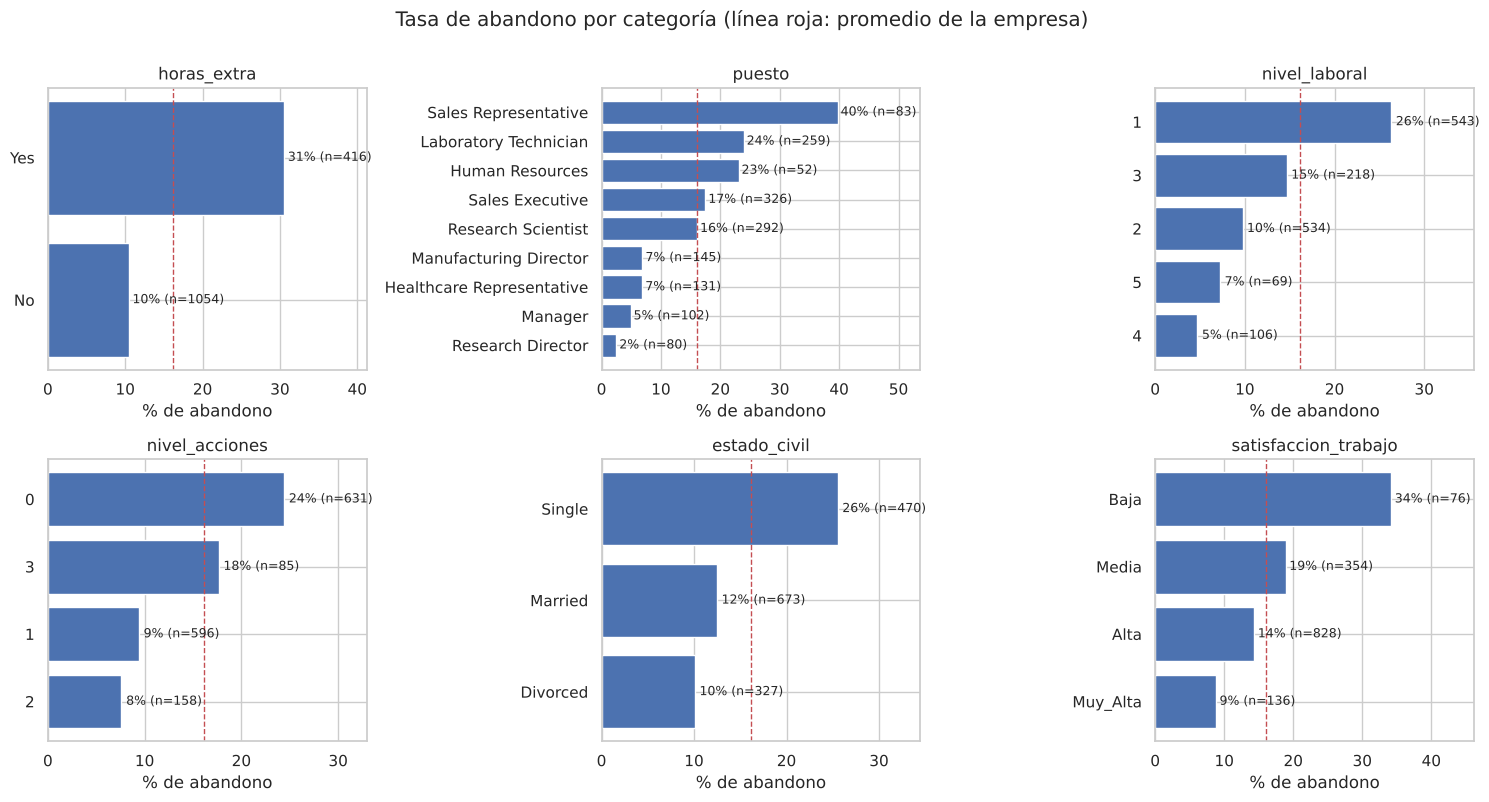

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axes.flat, asoc_cat.index[:6]):
    resumen = df.groupby(var)["abandono"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(resumen.index.astype(str), resumen["mean"] * 100, color="#4C72B0")
    ax.axvline(tasa * 100, color="#C44E52", ls="--", lw=1)
    for i, (m, n) in enumerate(zip(resumen["mean"], resumen["size"])):
        ax.text(m * 100 + 0.5, i, f"{m:.0%} (n={n})", va="center", fontsize=9)
    ax.set(title=var, xlabel="% de abandono")
    ax.set_xlim(0, resumen["mean"].max() * 100 * 1.35)
fig.suptitle("Tasa de abandono por categoría (línea roja: promedio de la empresa)", y=1.0)
plt.tight_layout(); plt.show()

In [9]:
numericas = [c for c in df.drop(columns="abandono").select_dtypes("number").columns if c not in categoricas]
filas = []
for var in numericas:
    se_fue, se_quedo = df.loc[df["abandono"] == 1, var], df.loc[df["abandono"] == 0, var]
    filas.append({
        "variable": var,
        "mediana se fue": se_fue.median(),
        "mediana se quedó": se_quedo.median(),
        "p-valor": stats.mannwhitneyu(se_fue, se_quedo).pvalue,
    })
asoc_num = pd.DataFrame(filas).sort_values("p-valor").set_index("variable")
asoc_num.style.format({"mediana se fue": "{:,.0f}", "mediana se quedó": "{:,.0f}", "p-valor": "{:.1e}"})

,mediana se fue,mediana se quedó,p-valor
variable,,,
anos_experiencia,7,10,2.4e-14
salario_mes,"3,202","5,204",3.0e-14
anos_compania,3,6,2.9e-13
anos_con_manager_actual,2,3,1.8e-11
edad,32,36,5.3e-11
distancia_casa,9,7,2.4e-03
anos_desde_ult_promocion,1,1,4.1e-02
num_formaciones_ult_ano,2,3,4.7e-02
num_empresas_anteriores,1,2,2.4e-01


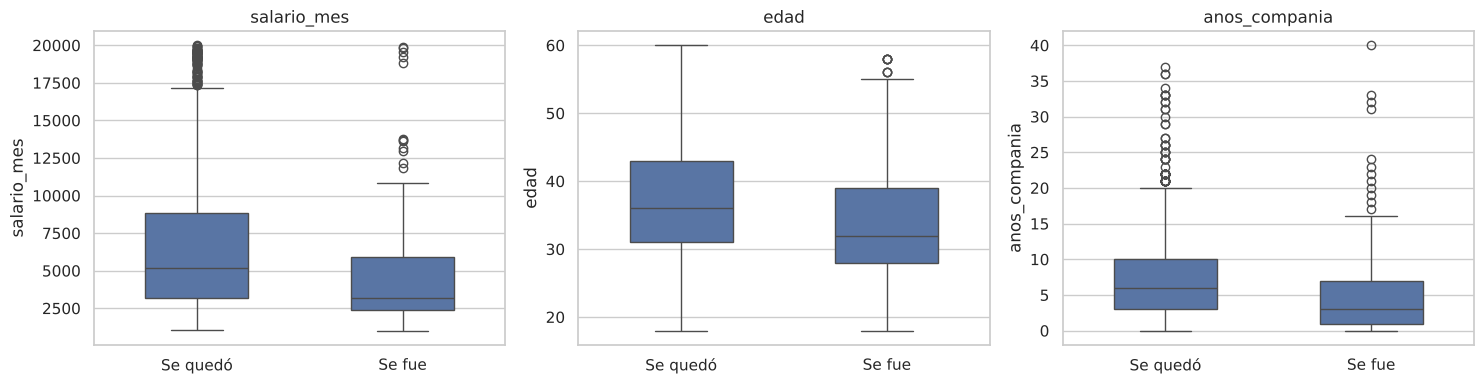

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["salario_mes", "edad", "anos_compania"]):
    sns.boxplot(data=df, x="abandono", y=var, ax=ax, color="#4C72B0", width=0.5)
    ax.set(xticks=[0, 1], xticklabels=["Se quedó", "Se fue"], xlabel="", title=var)
plt.tight_layout(); plt.show()

**Hallazgos (análisis bivariado, no implica causalidad):**

- **Horas extra y puesto** son las variables con mayor asociación (V de Cramér = 0.24). Quienes hacen horas extra se van tres veces más (31% frente a 10%). Por puesto, *Sales Representative* tiene un 40% de abandono, mientras que *Research Director* tiene un 2%.
- **Nivel laboral y acciones:** el nivel laboral 1 (26%) y los empleados sin acciones de la empresa (24%) superan con holgura el promedio de 16%.
- **Estado civil:** los solteros se van más del doble que los casados (26% frente a 12%).
- **Satisfacción e implicación bajas:** ambas llegan a 34% de abandono.
- **Educación:** el nivel primario tiene 32% de abandono frente a 8% en maestría. La asociación es más débil (V = 0.14).
- **Variables numéricas:** quienes se fueron tienen un salario mediano menor (3,202 frente a 5,204), menos años de experiencia (7 frente a 10) y de antigüedad (3 frente a 6), y son más jóvenes (32 frente a 36 años).
- **Sin asociación significativa:** la evaluación de desempeño (p = 0.99), el porcentaje de incremento salarial (p = 0.37) y el número de empresas anteriores (p = 0.24).

Muchas de estas variables están relacionadas entre sí (por ejemplo, nivel laboral, salario, edad y experiencia). El modelo de la sección 5 estima el efecto de cada una **manteniendo constantes las demás**.

## 4. ¿Cuánto cuesta la rotación?

Se usa como referencia el estudio *There Are Significant Business Costs to Replacing Employees* (Center for American Progress, 2012), que estima el costo de reemplazar a un empleado como porcentaje de su salario anual según el tramo salarial:

| Salario anual | Costo de reemplazo |
|---|---|
| Hasta 30,000 | 16.1% |
| 30,000 – 50,000 | 19.7% |
| 50,000 – 75,000 | 20.4% |
| Más de 75,000 | 21.0% |

El estudio está en dólares y la base no indica su moneda, así que se asume que los salarios están en dólares.

In [11]:
df["salario_ano"] = df["salario_mes"] * 12
tramos = [0, 30_000, 50_000, 75_000, np.inf]
porcentajes = [0.161, 0.197, 0.204, 0.210]
df["costo_reemplazo"] = df["salario_ano"] * pd.cut(df["salario_ano"], bins=tramos, labels=porcentajes).astype(float)

costo_total = df.loc[df["abandono"] == 1, "costo_reemplazo"].sum()
print(f"Costo estimado de las {df['abandono'].sum()} salidas: USD {costo_total:,.0f}")
print(f"Costo promedio por salida: USD {costo_total / df['abandono'].sum():,.0f}")

Costo estimado de las 237 salidas: USD 2,719,006
Costo promedio por salida: USD 11,473


In [12]:
costo_puesto = (df[df["abandono"] == 1].groupby("puesto")
                .agg(salidas=("abandono", "size"), costo=("costo_reemplazo", "sum"))
                .sort_values("costo", ascending=False))
costo_puesto["% del costo"] = (costo_puesto["costo"] / costo_total * 100).round(1)
costo_puesto["tasa de abandono"] = df.groupby("puesto")["abandono"].mean().reindex(costo_puesto.index).map("{:.0%}".format)
costo_puesto.style.format({"costo": "USD {:,.0f}", "% del costo": "{:.1f}"})

,salidas,costo,% del costo,tasa de abandono
puesto,,,,
Sales Executive,57,"USD 1,066,356",39.2,17%
Laboratory Technician,62,"USD 406,290",14.9,24%
Research Scientist,47,"USD 286,202",10.5,16%
Manager,5,"USD 211,647",7.8,5%
Healthcare Representative,9,"USD 193,530",7.1,7%
Manufacturing Director,10,"USD 183,787",6.8,7%
Sales Representative,33,"USD 169,291",6.2,40%
Human Resources,12,"USD 104,150",3.8,23%
Research Director,2,"USD 97,753",3.6,2%


## 5. Modelo de riesgo de abandono

### 5.1 Diseño

- **Partición:** 70% entrenamiento y 30% prueba, **estratificada** para conservar la tasa de abandono de 16% en ambas partes.
- **Variables:** las 24 predictoras que quedaron tras la limpieza. **No** se incluyen `salario_ano` ni `costo_reemplazo`, porque son cálculos derivados del salario.
- **Preprocesamiento en un pipeline:** imputación por moda y one-hot encoding para las categóricas, y estandarización para las numéricas. Todo se ajusta solo con los datos de entrenamiento de cada iteración.
- **Comparación:** un modelo base que no aprende nada (*dummy*), un árbol de decisión, un random forest y una regresión logística, con **validación cruzada estratificada de 5 particiones**.
- **Métricas:** ROC-AUC (capacidad de ordenar por riesgo) y precisión promedio (*average precision*, más exigente cuando la clase positiva es minoritaria).

In [13]:
X = df.drop(columns=["abandono", "salario_ano", "costo_reemplazo"])
y = df["abandono"]
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

preprocesamiento = ColumnTransformer([
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), cat_cols),
    ("num", StandardScaler(), num_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEMILLA)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} ({y_train.mean():.1%} abandono) | Prueba: {len(X_test)} ({y_test.mean():.1%} abandono)")

Entrenamiento: 1029 (16.1% abandono) | Prueba: 441 (16.1% abandono)


In [14]:
candidatos = {
    "Modelo base (dummy)": DummyClassifier(strategy="prior"),
    "Árbol de decisión (profundidad 4)": DecisionTreeClassifier(max_depth=4, random_state=SEMILLA),
    "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1),
    "Regresión logística": LogisticRegression(max_iter=3000),
}

comparacion = []
for nombre, modelo in candidatos.items():
    pipe = Pipeline([("prep", preprocesamiento), ("modelo", modelo)])
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    ap = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    comparacion.append({"modelo": nombre, "ROC-AUC (media CV)": auc.mean(), "ROC-AUC (desv. CV)": auc.std(),
                        "Precisión promedio (media CV)": ap.mean()})
comparacion = pd.DataFrame(comparacion).set_index("modelo")
comparacion.round(3)

,ROC-AUC (media CV),ROC-AUC (desv. CV),Precisión promedio (media CV)
modelo,,,
Modelo base (dummy),0.500,0.000,0.161
Árbol de decisión (profundidad 4),0.686,0.063,0.361
Random forest,0.811,0.038,0.576
Regresión logística,0.830,0.051,0.582


La regresión logística supera a los modelos de árboles y es, además, la más interpretable. El árbol de decisión de profundidad 4, que era el modelo de la versión original, queda claramente por debajo cuando se evalúa con validación cruzada en vez de una sola partición.

### 5.2 Ajuste de la regularización

In [15]:
busqueda = GridSearchCV(
    Pipeline([("prep", preprocesamiento), ("modelo", LogisticRegression(max_iter=3000))]),
    param_grid={"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    cv=cv, scoring="roc_auc",
).fit(X_train, y_train)

print(f"Mejor C: {busqueda.best_params_['modelo__C']} | ROC-AUC en validación cruzada: {busqueda.best_score_:.3f}")
modelo_final = busqueda.best_estimator_

Mejor C: 0.3 | ROC-AUC en validación cruzada: 0.831


### 5.3 Evaluación en el conjunto de prueba

El conjunto de prueba no se usó en ninguna decisión anterior. El umbral de clasificación se elige con predicciones *fuera de muestra* del entrenamiento, maximizando el F1.

In [16]:
prob_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
umbrales = np.arange(0.10, 0.61, 0.01)
umbral = umbrales[np.argmax([f1_score(y_train, prob_oof >= u) for u in umbrales])]

prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= umbral).astype(int)

metricas = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, prob_test),
    "Precisión promedio": average_precision_score(y_test, prob_test),
    "Umbral elegido": umbral,
    "Precisión (de los marcados en riesgo, cuántos se fueron)": precision_score(y_test, pred_test),
    "Recall (de los que se fueron, cuántos fueron marcados)": recall_score(y_test, pred_test),
}).round(3)
metricas

ROC-AUC                                                     0.793
Precisión promedio                                          0.567
Umbral elegido                                              0.250
Precisión (de los marcados en riesgo, cuántos se fueron)    0.451
Recall (de los que se fueron, cuántos fueron marcados)      0.577
dtype: float64

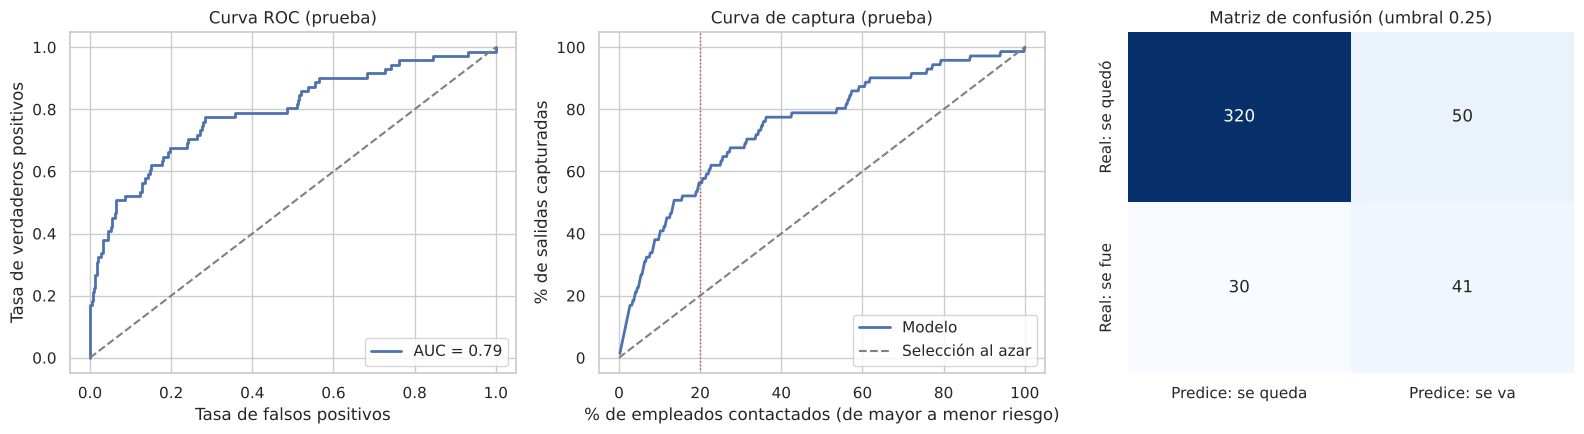

Contactando al 10% de mayor riesgo se captura el 39% de las salidas
Contactando al 20% de mayor riesgo se captura el 56% de las salidas
Contactando al 30% de mayor riesgo se captura el 68% de las salidas


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

fpr, tpr, _ = roc_curve(y_test, prob_test)
axes[0].plot(fpr, tpr, color="#4C72B0", lw=2, label=f"AUC = {roc_auc_score(y_test, prob_test):.2f}")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--")
axes[0].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axes[0].legend(loc="lower right")

orden = np.argsort(-prob_test)
capturados = np.cumsum(y_test.to_numpy()[orden]) / y_test.sum()
fraccion = np.arange(1, len(orden) + 1) / len(orden)
axes[1].plot(fraccion * 100, capturados * 100, color="#4C72B0", lw=2, label="Modelo")
axes[1].plot([0, 100], [0, 100], color="grey", ls="--", label="Selección al azar")
axes[1].axvline(20, color="#C44E52", ls=":", lw=1)
axes[1].set(title="Curva de captura (prueba)", xlabel="% de empleados contactados (de mayor a menor riesgo)",
            ylabel="% de salidas capturadas")
axes[1].legend(loc="lower right")

cm = confusion_matrix(y_test, pred_test)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Predice: se queda", "Predice: se va"], yticklabels=["Real: se quedó", "Real: se fue"])
axes[2].set(title=f"Matriz de confusión (umbral {umbral:.2f})")
plt.tight_layout(); plt.show()

for f in (0.1, 0.2, 0.3):
    print(f"Contactando al {f:.0%} de mayor riesgo se captura el {capturados[int(len(orden) * f) - 1]:.0%} de las salidas")

### 5.4 ¿Qué variables pesan más en el modelo?

En una regresión logística, el **odds ratio** indica cuánto se multiplican las probabilidades relativas de abandono. Para las variables numéricas se interpreta por cada desviación estándar de aumento. Para las categóricas, frente a la categoría de referencia de esa variable (la primera en orden alfabético, listada debajo del gráfico).

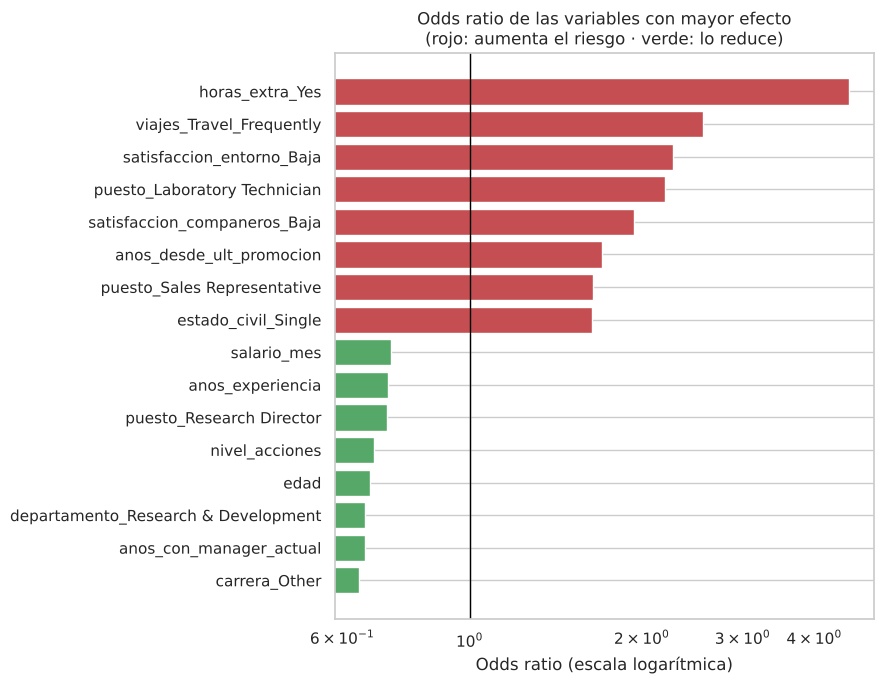

Categorías de referencia: {'viajes': 'Non-Travel', 'departamento': 'Human Resources', 'educacion': 'Master', 'carrera': 'Human Resources', 'satisfaccion_entorno': 'Alta', 'implicacion': 'Alta', 'puesto': 'Healthcare Representative', 'satisfaccion_trabajo': 'Alta', 'estado_civil': 'Divorced', 'horas_extra': 'No', 'evaluacion': 'Alta', 'satisfaccion_companeros': 'Alta'}

horas_extra_Yes                        4.61
viajes_Travel_Frequently               2.56
satisfaccion_entorno_Baja              2.26
puesto_Laboratory Technician           2.19
satisfaccion_companeros_Baja           1.94
anos_desde_ult_promocion               1.70
puesto_Sales Representative            1.64
estado_civil_Single                    1.63
num_empresas_anteriores                1.53
satisfaccion_trabajo_Baja              1.48
implicacion_Baja                       1.42
distancia_casa                         1.41
educacion_Primaria                     1.38
puesto_Human Resources                 1.34
viajes_Trave

In [18]:
nombres = modelo_final.named_steps["prep"].get_feature_names_out()
nombres = [n.replace("cat__", "").replace("num__", "") for n in nombres]
coefs = pd.Series(modelo_final.named_steps["modelo"].coef_[0], index=nombres)
odds = np.exp(coefs).sort_values()
extremos = pd.concat([odds.head(8), odds.tail(8)])

fig, ax = plt.subplots(figsize=(9, 7))
colores = ["#55A868" if v < 1 else "#C44E52" for v in extremos]
ax.barh(extremos.index, extremos.values, color=colores)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set(title="Odds ratio de las variables con mayor efecto\n(rojo: aumenta el riesgo · verde: lo reduce)", xlabel="Odds ratio (escala logarítmica)")
plt.tight_layout(); plt.show()

referencias = {c: sorted(X_train[c].dropna().unique())[0] for c in cat_cols}
print("Categorías de referencia:", referencias)
print()
print(odds.round(2).sort_values(ascending=False).to_string())

**Lectura del modelo (efectos ajustados por las demás variables, son asociaciones y no causas):**

- **Horas extra** es el factor de mayor peso: multiplica las probabilidades relativas de abandono por **4.6**.
- **Viajar con frecuencia** las multiplica por 2.6 frente a no viajar.
- **Baja satisfacción con el entorno** (×2.3) y **con los compañeros** (×1.9) frente a satisfacción alta. Esta última no era significativa en el análisis bivariado, pero sí aparece cuando se controla por las demás variables.
- **Puesto:** *Laboratory Technician* (×2.2) y *Sales Representative* (×1.6) frente a *Healthcare Representative*.
- **Más tiempo desde la última promoción** (×1.7 por desviación estándar) y **ser soltero** (×1.6 frente a divorciado).
- **Factores protectores:** más edad, más años con el mismo jefe, más acciones de la empresa, mayor salario y más experiencia (entre ×0.66 y ×0.73 por desviación estándar).

Una vez que se controla por el puesto y la carga de trabajo, el **nivel educativo pierde fuerza** (primaria ×1.4): no es uno de los factores principales, como sugería el análisis bivariado.

## 6. Uso del modelo: priorizar la retención

Para asignar un riesgo a **cada** empleado sin que el modelo califique a personas que ya vio durante su entrenamiento, se usan predicciones *fuera de muestra* con validación cruzada sobre toda la base. Después se filtra a los empleados **activos** (los que no se han ido), que son sobre quienes se puede actuar.

El **costo esperado** de cada empleado es su probabilidad de abandono multiplicada por su costo de reemplazo.

In [19]:
df["prob_abandono"] = cross_val_predict(modelo_final, X, y, cv=cv, method="predict_proba")[:, 1]
df["costo_esperado"] = df["prob_abandono"] * df["costo_reemplazo"]

activos = df[df["abandono"] == 0].copy()
activos["riesgo"] = np.where(activos["prob_abandono"] >= umbral, "Alto", "Bajo")

en_riesgo = activos[activos["riesgo"] == "Alto"]
print(f"Empleados activos: {len(activos):,}")
print(f"Activos en riesgo alto (probabilidad >= {umbral:.2f}): {len(en_riesgo)} ({len(en_riesgo)/len(activos):.1%})")
print(f"Salidas esperadas entre los activos (suma de probabilidades): {activos['prob_abandono'].sum():.0f}")
print(f"Costo esperado de la rotación entre los activos: USD {activos['costo_esperado'].sum():,.0f}")
print(f"  ...de ese costo, concentrado en los de riesgo alto: USD {en_riesgo['costo_esperado'].sum():,.0f} ({en_riesgo['costo_esperado'].sum()/activos['costo_esperado'].sum():.0%})")

Empleados activos: 1,233
Activos en riesgo alto (probabilidad >= 0.25): 170 (13.8%)
Salidas esperadas entre los activos (suma de probabilidades): 147
Costo esperado de la rotación entre los activos: USD 1,889,297
  ...de ese costo, concentrado en los de riesgo alto: USD 729,071 (39%)


In [20]:
por_puesto = activos.groupby("puesto").agg(
    activos=("prob_abandono", "size"),
    en_riesgo_alto=("riesgo", lambda s: (s == "Alto").sum()),
    probabilidad_media=("prob_abandono", "mean"),
    salidas_esperadas=("prob_abandono", "sum"),
    costo_esperado=("costo_esperado", "sum"),
).sort_values("costo_esperado", ascending=False)
por_puesto.style.format({"probabilidad_media": "{:.0%}", "salidas_esperadas": "{:.1f}", "costo_esperado": "USD {:,.0f}"})

,activos,en_riesgo_alto,probabilidad_media,salidas_esperadas,costo_esperado
puesto,,,,,
Sales Executive,269,36,13%,34.7,"USD 553,151"
Laboratory Technician,197,45,17%,33.9,"USD 272,926"
Research Scientist,245,35,12%,30.1,"USD 231,176"
Manager,97,3,5%,4.5,"USD 191,476"
Healthcare Representative,122,9,9%,10.7,"USD 189,428"
Manufacturing Director,135,8,7%,9.7,"USD 175,308"
Research Director,78,1,4%,3.1,"USD 116,970"
Sales Representative,50,26,28%,14.2,"USD 95,700"
Human Resources,40,7,15%,5.9,"USD 63,163"


In [21]:
cols = ["puesto", "departamento", "horas_extra", "estado_civil", "salario_mes", "prob_abandono", "costo_esperado"]
activos.sort_values("prob_abandono", ascending=False)[cols].head(10).style.format(
    {"prob_abandono": "{:.0%}", "costo_esperado": "USD {:,.0f}", "salario_mes": "{:,.0f}"})

,puesto,departamento,horas_extra,estado_civil,salario_mes,prob_abandono,costo_esperado
id,,,,,,,
792,Laboratory Technician,Research & Development,No,Divorced,"4,364",85%,"USD 9,092"
1646,Research Scientist,Research & Development,Yes,Single,"3,760",78%,"USD 6,975"
783,Sales Representative,Sales,No,Single,"6,632",74%,"USD 12,375"
72,Sales Executive,Sales,Yes,Married,"4,157",73%,"USD 7,187"
475,Sales Executive,Sales,Yes,Married,"4,736",69%,"USD 7,946"
1198,Laboratory Technician,Research & Development,No,Single,"3,033",64%,"USD 4,564"
1961,Sales Representative,Sales,No,Single,"2,858",62%,"USD 4,220"
925,Sales Representative,Sales,Yes,Single,"3,294",62%,"USD 4,833"
669,Sales Representative,Sales,No,Single,"3,447",62%,"USD 5,016"


In [22]:
# Exporta el scoring de los empleados activos para el dashboard de Tableau
import os
os.makedirs("outputs", exist_ok=True)
exportar = activos[["edad", "departamento", "puesto", "horas_extra", "estado_civil", "salario_mes",
                    "costo_reemplazo", "prob_abandono", "costo_esperado", "riesgo"]]
exportar.round(4).to_csv("outputs/scoring_empleados_activos.csv", encoding="utf-8")
print(f"Archivo exportado: outputs/scoring_empleados_activos.csv ({len(exportar)} filas)")

Archivo exportado: outputs/scoring_empleados_activos.csv (1233 filas)


## 7. Recomendaciones

1. **Carga de trabajo:** las horas extra son el factor con mayor efecto. Revisar la asignación de horas extra en los puestos donde se concentran es la palanca con mayor potencial.
2. **Priorizar dos puestos:**
   - *Sales Representative* tiene la probabilidad media de abandono más alta entre los activos (28%), con 26 de sus 50 empleados en riesgo alto.
   - *Laboratory Technician* tiene el mayor número de empleados en riesgo alto (45).
3. **Asignar el presupuesto por costo, no solo por tasa:** *Sales Executive* concentra el mayor costo esperado (USD 553 mil) por sus salarios más altos, aunque su tasa de abandono es moderada.
4. **Plan de carrera:** el tiempo desde la última promoción aumenta el riesgo y tener acciones de la empresa lo reduce. Revisar los criterios de promoción y de participación accionaria en los niveles iniciales.
5. **Regla operativa:** usar el scoring para contactar primero al 20% de empleados con mayor riesgo, que concentra alrededor del 56% de las salidas. El costo esperado del grupo de riesgo alto (USD 729 mil) sirve como referencia para dimensionar el presupuesto de retención.

El archivo `outputs/scoring_empleados_activos.csv` alimenta el dashboard de Tableau con el riesgo y el costo esperado de cada empleado activo.

## 8. Limitaciones

- **Datos ficticios y de un solo corte:** la base es un conjunto de práctica, sin fechas. No se sabe cuándo se fue cada empleado ni cómo eran sus condiciones antes de irse, por lo que el modelo identifica **asociaciones**, no causas.
- **Costo de reemplazo de referencia:** los porcentajes vienen de un estudio de Estados Unidos y se asume que los salarios están en dólares. El costo real depende de cada empresa.
- **Variables descartadas:** `sexo` no se pudo usar por su codificación inconsistente, y dos variables se eliminaron por exceso de nulos.
- **Validación limitada por el tamaño:** con 1,470 empleados y 237 salidas, las métricas tienen variabilidad (la desviación del ROC-AUC entre particiones ronda 0.05).